# Behavioral verification: comparable, indexed experiments

This notebook runs the reusable package implementation. P1 is a per-user
classifier trained with same-card impostors. P2 enrolls on genuine attempts
1–5 and probes genuine 6–10 plus same-card impostors. All scores retain
`(User ID, Is Genuine, Test ID)`; larger means more genuine.

Settings are fixed baselines, not selected on these evaluation results.
EER uses the complete ROC and the discrete nearest-crossing convention.
FRR at a target FAR is an evaluation-curve statistic, not a calibrated
deployment guarantee. A deployable threshold needs separate calibration.


In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from behavioral_ml import evaluation, experiment
from behavioral_ml.etl import infer_typist_candidates, load_data
from behavioral_ml.features import build_feature_sets

data_dir = Path(os.environ.get("KMT_DATA_DIR", "../data/raw_kmt_dataset"))
mouse_events, key_events = load_data(data_dir)
feature_sets = build_feature_sets(mouse_events, key_events)
assert len(feature_sets["keys"]) == 1760
assert not np.isinf(feature_sets["keys_mouse"].to_numpy(dtype=float)).any()
pd.DataFrame({name: {"attempts": len(frame), "features": frame.shape[1]}
              for name, frame in feature_sets.items()}).T


,attempts,features
keys,1760,18
mouse,1760,21
keys_mouse,1760,39


## Feature and identity audit

The matrix compares 18 keyboard features, 21 mouse features, and their
39-feature combination. Counts represent physical actions; release-only
navigation events are excluded from observed-press timings. Tied-time mouse
coordinates contribute to geometry, while undefined rates remain missing.

KMT records the claimed card owner, not the impostor's actual ID. We retain
every preceding genuine-session candidate within one hour. This is a
timestamp assumption, not ground truth; multiple candidates are ambiguous.


In [2]:
typist_candidates = infer_typist_candidates(key_events)
impostor_candidates = typist_candidates.loc[~typist_candidates.index.get_level_values("Is Genuine")]
identity_audit = impostor_candidates.map(len).value_counts().sort_index().rename("attempts").rename_axis("plausible_typists")
display(pd.DataFrame({"mouse_events": [len(mouse_events)], "key_events": [len(key_events)]}))
identity_audit


,mouse_events,key_events
0,706984,172563


plausible_typists
1    519
2    270
3     84
4      7
Name: attempts, dtype: int64

## Fixed baseline matrix

Seven personal methods × three feature sets give 21 configurations: median/std
Manhattan, mean/MAD Manhattan, OCSVM, Isolation Forest, kNN, LOF, and HBOS.
Each uses genuine attempts 1–5 for enrollment and the same 1,320 probe rows.
Imputation and scaling fit on enrollment only. kNN uses three neighbors, mean
Manhattan distance; LOF uses two neighbors and novelty mode; HBOS uses three
bins. PyOD scores are negated so larger always means more genuine. These are
fixed exploratory settings, not choices optimized on the displayed results.
Five rows provide little support for local-density or histogram estimation.
ECOD/COPOD are excluded because their stock scores depend on the probe batch.

Three keyboard-only references accompany the matrix: P1 logistic regression
with stratified five-fold scores and two global verifiers. Global models use
absolute template differences and five-fold splits of claimed owners, excluding
a row unless its owner and every plausible typist are on the same side.
Their identity separation is conditional on timestamp attribution. Unknown and
cross-fold candidates are excluded. The global runs therefore have fewer probes.


In [3]:
experiments = experiment.run_baselines(feature_sets, typist_candidates, n_enroll=5, n_splits=5, random_state=42)
all_probe_results = experiment.results_table(experiments)
all_probe_results


,n_probes,n_genuine,n_impostor,n_users_with_both_classes,pooled_auc,pooled_eer,per_user_auc_mean,per_user_auc_median,pooled_frr_at_far_0.01,per_user_eer_mean,per_user_eer_median,per_user_eer_iqr
experiment,,,,,,,,,,,,
p2.template_l1.keys,1320.0,440.0,880.0,88.0,0.910878,0.170455,0.941818,0.980,0.811364,0.119886,0.150,0.2000
p2.scaled_l1.keys,1320.0,440.0,880.0,88.0,0.906206,0.172727,0.942955,0.970,0.838636,0.118182,0.150,0.2000
p2.ocsvm.keys,1320.0,440.0,880.0,88.0,0.895394,0.161364,0.946477,0.980,0.745455,0.112500,0.150,0.2000
p2.iforest.keys,1320.0,440.0,880.0,88.0,0.720724,0.332955,0.753295,0.790,0.952273,0.309091,0.275,0.2000
p2.knn.keys,1320.0,440.0,880.0,88.0,0.910553,0.170455,0.955455,0.980,0.772727,0.101136,0.150,0.2000
p2.lof.keys,1320.0,440.0,880.0,88.0,0.920848,0.143182,0.945568,0.980,0.913636,0.116477,0.150,0.2000
p2.hbos.keys,1320.0,440.0,880.0,88.0,0.744863,0.343182,0.883182,0.925,0.847727,0.196023,0.200,0.0625
p2.template_l1.mouse,1320.0,440.0,880.0,88.0,0.795780,0.265341,0.829318,0.840,0.927273,0.226136,0.200,0.2000
p2.scaled_l1.mouse,1320.0,440.0,880.0,88.0,0.799008,0.258523,0.827273,0.840,0.927273,0.229545,0.200,0.2000


## Personal detector and modality comparison

This table uses the full, identical personal probe set. Means are over users;
pooled metrics remain separate in the full results table. Compare each method
across modalities without changing enrollment or probe identities. This is an
exploratory ablation, with no parameter or feature selection claim.


In [4]:
personal_rows = all_probe_results.loc[all_probe_results.index.str.count(r"\.") == 2].copy()
personal_rows["detector"] = personal_rows.index.str.split(".").str[1]
personal_rows["features"] = personal_rows.index.str.split(".").str[2]
personal_rows.pivot(index="detector", columns="features",
                    values=["per_user_auc_mean", "per_user_eer_mean"])


per_user_auc_mean                      per_user_eer_mean  \
features                 keys keys_mouse     mouse              keys   
detector                                                               
hbos                 0.883182   0.894318  0.750000          0.196023   
iforest              0.753295   0.790795  0.738295          0.309091   
knn                  0.955455   0.926591  0.827500          0.101136   
lof                  0.945568   0.909205  0.803182          0.116477   
ocsvm                0.946477   0.915114  0.808523          0.112500   
scaled_l1            0.942955   0.922955  0.827273          0.118182   
template_l1          0.941818   0.920682  0.829318          0.119886   

                                  
features    keys_mouse     mouse  
detector                          
hbos          0.177841  0.311364  
iforest       0.277841  0.332955  
knn           0.114773  0.226705  
lof           0.135795  0.242045  
ocsvm         0.133523  0.241477  
scaled_l1     0.124432  0.229545  
template_l1   0.128977  0.226136

## Compare identical probes

The table above documents coverage; its rows do not all use the same probe
set. Below, every method is restricted to the global verifiers' common P2
probes. P1 still has access to impostor training data, so it remains a
different training-information comparison. Pooled metrics use one raw score
threshold; per-user metrics are separate descriptive summaries.

Some users have no retained impostor probe. Their per-user AUC/EER is
undefined and excluded from those summaries; the table reports the number
of users with both classes. Sparse impostor probes make low-FAR and per-user
estimates coarse. Independent per-user score scales are not calibrated.


In [5]:
comparable = experiment.common_probe_scores(experiments)
common_probe_results = experiment.results_table(comparable)
common_probe_results


,n_probes,n_genuine,n_impostor,n_users_with_both_classes,pooled_auc,pooled_eer,per_user_auc_mean,per_user_auc_median,pooled_frr_at_far_0.01,per_user_eer_mean,per_user_eer_median,per_user_eer_iqr
experiment,,,,,,,,,,,,
p2.template_l1.keys,552.0,440.0,112.0,61.0,0.915950,0.179058,0.925683,1.000000,0.736364,0.084426,0.000,0.000000
p2.scaled_l1.keys,552.0,440.0,112.0,61.0,0.908157,0.188068,0.927322,1.000000,0.836364,0.085246,0.000,0.000000
p2.ocsvm.keys,552.0,440.0,112.0,61.0,0.906717,0.159903,0.921038,1.000000,0.661364,0.073224,0.000,0.100000
p2.iforest.keys,552.0,440.0,112.0,61.0,0.682559,0.385146,0.746721,0.800000,0.950000,0.274044,0.200,0.550000
p2.knn.keys,552.0,440.0,112.0,61.0,0.915889,0.170049,0.932240,1.000000,0.709091,0.083607,0.000,0.000000
p2.lof.keys,552.0,440.0,112.0,61.0,0.915676,0.149756,0.920219,1.000000,0.922727,0.078962,0.000,0.000000
p2.hbos.keys,552.0,440.0,112.0,61.0,0.757041,0.338961,0.893989,1.000000,0.672727,0.110383,0.000,0.100000
p2.template_l1.mouse,552.0,440.0,112.0,61.0,0.813332,0.259010,0.815847,0.800000,0.879545,0.203825,0.100,0.366667
p2.scaled_l1.mouse,552.0,440.0,112.0,61.0,0.819785,0.240990,0.815847,0.800000,0.852273,0.197541,0.100,0.366667


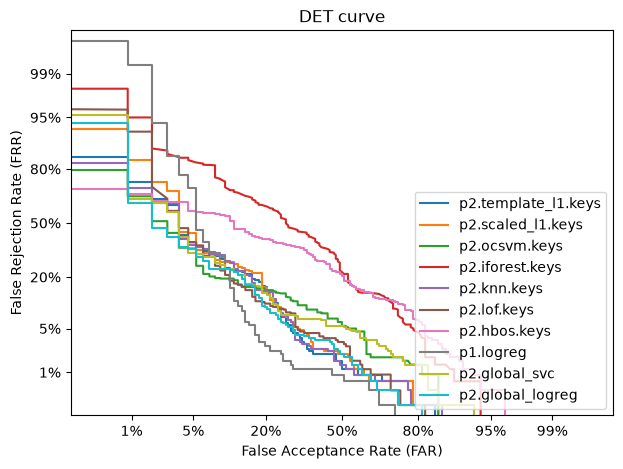

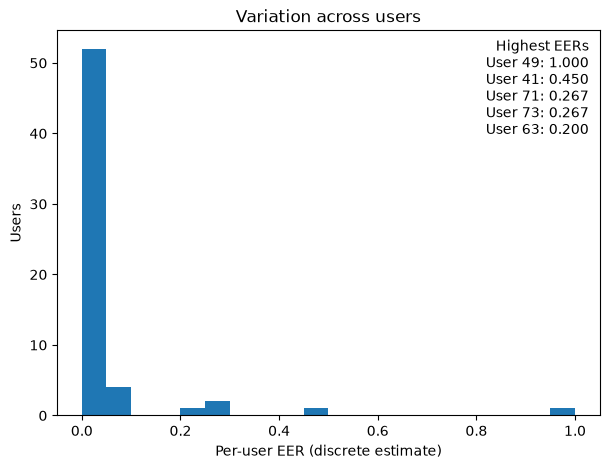

,n_genuine,n_impostor,auc,eer
User ID,,,,
49,5,1,0.000000,1.000000
41,5,2,0.700000,0.450000
71,5,3,0.933333,0.266667
73,5,3,0.933333,0.266667
63,5,1,0.600000,0.200000
37,5,1,0.800000,0.100000
1,5,2,0.900000,0.100000
11,5,1,0.800000,0.100000
32,5,2,0.900000,0.100000


In [6]:
# Keep the DET overlay readable: keyboard methods and the three references.
keyboard_comparison = {name: scores for name, scores in comparable.items()
                       if scores.attrs["feature_set"] == "keys"}
evaluation.plot_det_curves(keyboard_comparison)
plt.show()
per_user = evaluation.per_user_metrics(comparable["p2.global_logreg"])
evaluation.plot_per_user_eer(per_user)
plt.show()
per_user.sort_values("eer", ascending=False).head(10)


## Within-session warm-up and limits

A genuine user's attempts come from one sitting. Repetition, content
familiarity, and identity are coupled; this experiment cannot establish
cross-day stability or resistance to practised attackers. The plot measures
the span of recorded keyboard events, rather than total GUI completion time.


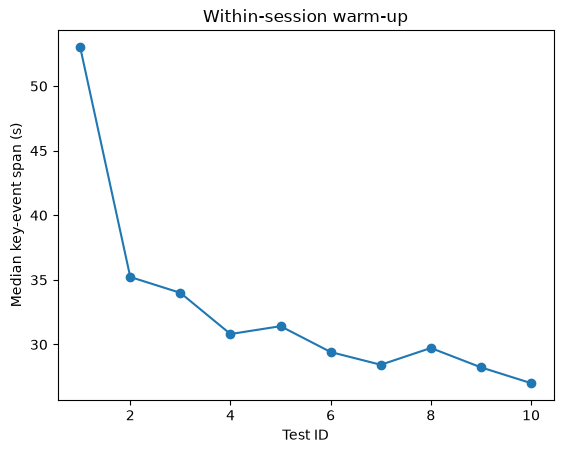

In [7]:
windows = key_events.groupby(level=["User ID", "Is Genuine", "Test ID"])["Epoch"].agg(["min", "max"])
spans = windows["max"] - windows["min"]
genuine_spans = spans.loc[spans.index.get_level_values("Is Genuine")]
genuine_spans.groupby(level="Test ID").median().plot(marker="o", ylabel="Median key-event span (s)", title="Within-session warm-up")
plt.show()


## Reproducibility and MLflow

Save indexed scores, fold IDs, common-probe/per-user tables, resolved settings,
package versions, source hashes, and raw-file checksums under `artifacts/`.
Explicit MLflow logging creates a parent matrix run and one child per complete
configuration. Child runs contain metrics, predictions, per-user tables, and
ROC/DET plots. SQLite tracking and model artifacts use absolute local paths;
`MLFLOW_TRACKING_URI` can select another backend. Scores are not calibrated
probabilities, and no deployment threshold is selected here.


In [8]:
from behavioral_ml.tracking import log_experiments

output_dir = Path("../artifacts")
experiment.write_results(experiments, output_dir, data_dir)
parent_run_id = log_experiments(experiments, output_dir)
print(f"Wrote artifacts to {output_dir.resolve()}; MLflow parent run: {parent_run_id}")


2026/10/28 15:50:30 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Volumes/Workspace/01_Projects/behavioral-ml/.venv/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Wrote artifacts to /Volumes/Workspace/01_Projects/behavioral-ml/artifacts; MLflow parent run: 9c8b6c076275442c8696349fb7d9e96f
